In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
print(tf.__version__)

2.20.0


In [11]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
!unzip -q "/content/drive/MyDrive/archive (3).zip" -d /content/PlantVillage

In [13]:
data_dir = "/content/PlantVillage/PlantVillage"

img_size = (224, 224)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

class_names = train_ds.class_names
print(class_names)
print("Number of classes:", len(class_names))

Found 20638 files belonging to 15 classes.
Using 16511 files for training.
Found 20638 files belonging to 15 classes.
Using 4127 files for validation.
['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Number of classes: 15


In [14]:
normalization_layer = tf.keras.layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

In [15]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

In [16]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)

model = tf.keras.Model(inputs, outputs)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,199 (8.69 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 54s 84ms/step - accuracy: 0.7227 - loss: 0.8915 - val_accuracy: 0.8357 - val_loss: 0.5185
Epoch 2/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 44s 84ms/step - accuracy: 0.8431 - loss: 0.4884 - val_accuracy: 0.8638 - val_loss: 0.4263
Epoch 3/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 41s 79ms/step - accuracy: 0.8592 - loss: 0.4207 - val_accuracy: 0.8793 - val_loss: 0.3839
Epoch 4/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 44s 85ms/step - accuracy: 0.8734 - loss: 0.3816 - val_accuracy: 0.8808 - val_loss: 0.3591
Epoch 5/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 44s 85ms/step - accuracy: 0.8787 - loss: 0.3624 - val_accuracy: 0.8825 - val_loss: 0.3483
Epoch 6/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 41s 79ms/step - accuracy: 0.8872 - loss: 0.3391 - val_accuracy: 0.8762 - val_loss: 0.3596
Epoch 7/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 41s 80ms/step - accuracy: 0.8857 - loss: 0.3401 - val_accuracy: 0.8951 - val_loss: 0.3205
Epoch 8/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 44s 85ms/step - accuracy: 0.8884 - loss: 0.3269 - 

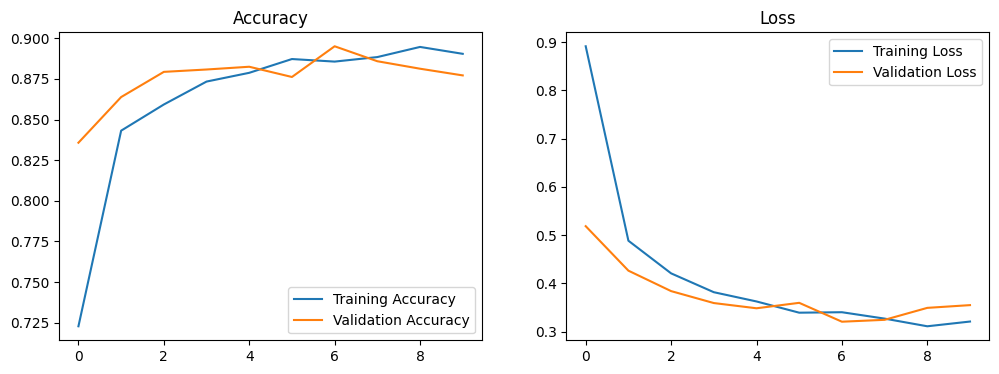

In [18]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.91      0.98      0.94       176
                     Pepper__bell___healthy       0.99      0.96      0.97       280
                      Potato___Early_blight       0.99      0.96      0.98       194
                       Potato___Late_blight       0.98      0.89      0.93       224
                           Potato___healthy       0.87      0.93      0.90        29
                      Tomato_Bacterial_spot       0.86      0.93      0.89       414
                        Tomato_Early_blight       0.99      0.34      0.51       200
                         Tomato_Late_blight       0.78      0.96      0.86       369
                           Tomato_Leaf_Mold       0.89      0.89      0.89       208
                  Tomato_Septoria_leaf_spot       0.83      0.88      0.85       337
Tomato_Spider_mites_Two_spotted_spider_mite       0.95      0.63

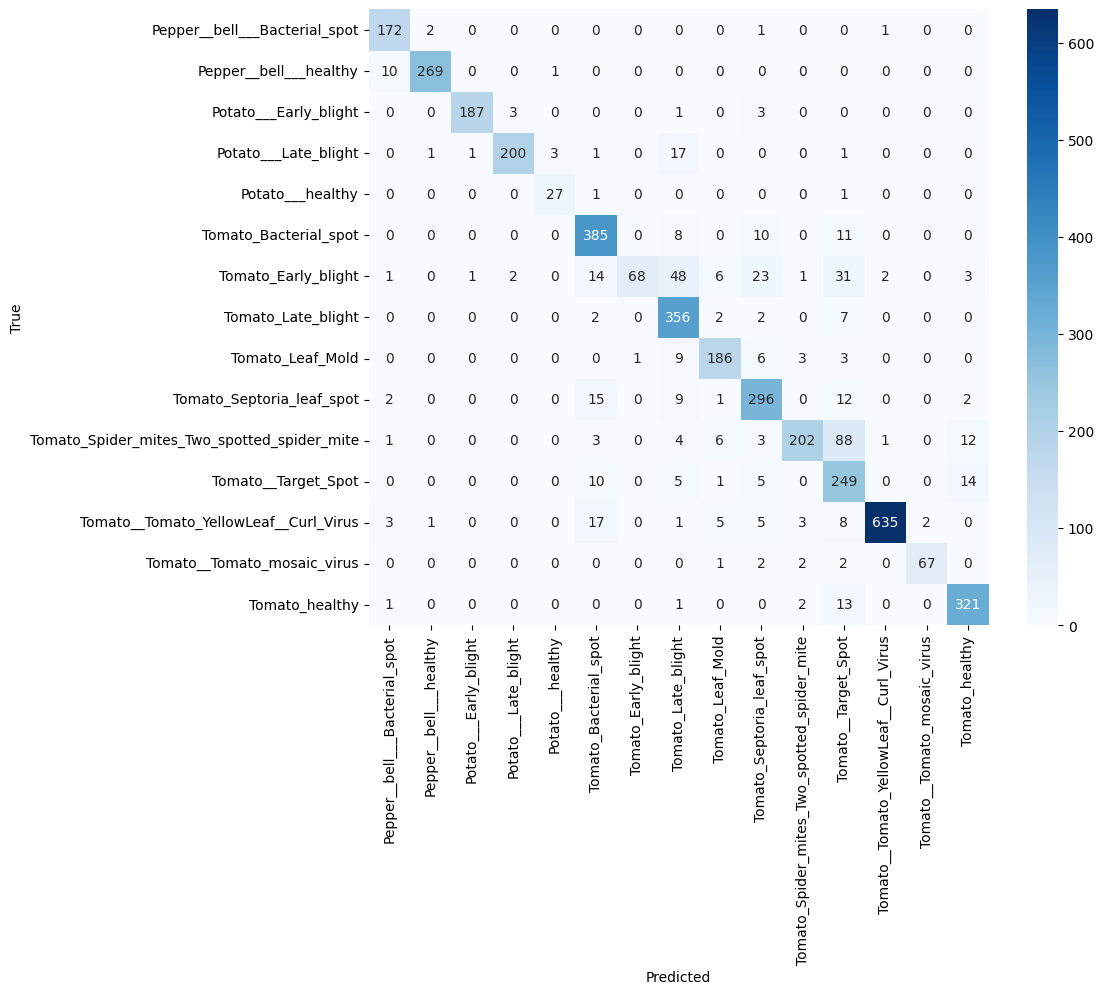

In [19]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

In [20]:
def predict_disease(img_path):
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)  # create a batch of 1
    img_array = img_array / 255.0  # normalize, same as training

    predictions = model.predict(img_array, verbose=0)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = 100 * np.max(predictions[0])

    print(f"Predicted: {predicted_class}")
    print(f"Confidence: {confidence:.2f}%")

    plt.imshow(img)
    plt.axis('off')
    plt.title(f"{predicted_class} ({confidence:.2f}%)")
    plt.show()

Predicted: Tomato__Target_Spot
Confidence: 60.46%


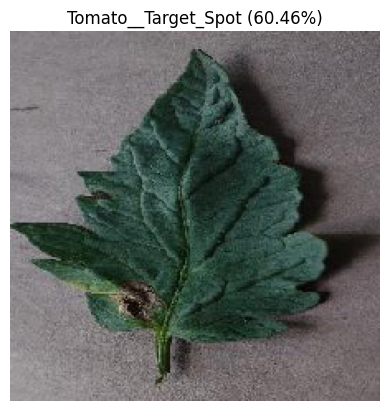

In [23]:
# Pick any image path from your dataset to test, e.g.:
sample_path = "/content/PlantVillage/PlantVillage/Tomato_Early_blight/" + os.listdir("/content/PlantVillage/PlantVillage/Tomato_Early_blight")[0]

predict_disease(sample_path)

In [24]:
model.save('/content/drive/MyDrive/plant_disease_model.h5')

Predicted: Tomato_healthy
Confidence: 93.39%


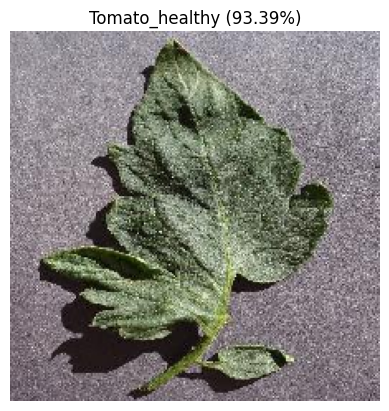

In [25]:
sample_path = "/content/PlantVillage/PlantVillage/Tomato_healthy/" + os.listdir("/content/PlantVillage/PlantVillage/Tomato_healthy")[0]
predict_disease(sample_path)

Predicted: Potato___Late_blight
Confidence: 56.90%


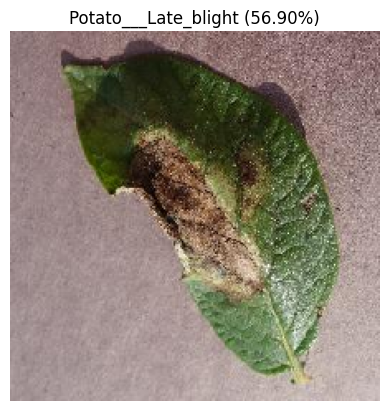

In [26]:
sample_path = "/content/PlantVillage/PlantVillage/Potato___Late_blight/" + os.listdir("/content/PlantVillage/PlantVillage/Potato___Late_blight")[0]
predict_disease(sample_path)

In [27]:
from google.colab import files

uploaded = files.upload()   # click "Choose Files" and pick your leaf photo

Saving Screenshot 2026-08-26 150812.png to Screenshot 2026-08-26 150812 (1).png


Predicted: Pepper__bell___Bacterial_spot
Confidence: 93.81%


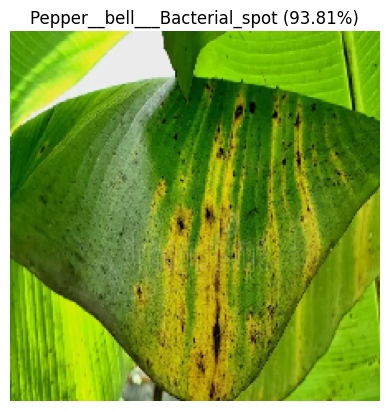

In [28]:
# Get the filename you just uploaded
my_image = list(uploaded.keys())[0]

predict_disease(my_image)

In [29]:
model.save('/content/drive/MyDrive/plant_disease_model.h5')

In [30]:
model.save('/content/drive/MyDrive/plant_disease_model.keras')

In [ ]:
def predict_disease(img_path):
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)
    img_array = img_array / 255.0

    predictions = model.predict(img_array, verbose=0)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = 100 * np.max(predictions[0])

    print(f"Predicted: {predicted_class}")
    print(f"Confidence: {confidence:.2f}%")

    plt.imshow(img)
    plt.axis('off')
    plt.title(f"{predicted_class} ({confidence:.2f}%)")
    plt.show()

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Ensure 'model' is defined. If not, load it.
if 'model' not in globals():
    print("Model not found in global scope. Attempting to load saved model.")
    try:
        model = tf.keras.models.load_model('/content/drive/MyDrive/plant_disease_model.h5')
        print("Model loaded from saved file.")
    except Exception as e:
        print(f"Error loading model: {e}. Please ensure the model was saved correctly in cell '6pA-laa50Cdt' and the path is correct, or re-run model definition cells (jbU5SxIGONk6, VauXq-JXZrfM).")

# Ensure 'class_names' is defined. If not, regenerate it from the data directory.
if 'class_names' not in globals():
    print("class_names not found in global scope. Attempting to regenerate from data directory.")
    try:
        data_dir = "/content/PlantVillage/PlantVillage"
        img_size = (224, 224)
        # Create a dummy dataset just to extract class names
        temp_ds_for_class_names = tf.keras.utils.image_dataset_from_directory(
            data_dir,
            image_size=img_size,
            batch_size=1, # Small batch size as we only need class names
            shuffle=False,
            labels='inferred',
            label_mode='int'
        )
        class_names = temp_ds_for_class_names.class_names
        print("class_names regenerated from data directory.")
    except Exception as e:
        print(f"Error regenerating class_names: {e}. Please ensure cell 'MTmTw7cROBtl' was executed or define class_names manually.")
        # Fallback to a hardcoded list if regeneration fails or is not possible (less ideal).
        class_names = ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
        print("Using hardcoded class_names as a fallback due to an error.")


my_image = list(uploaded.keys())[0]

# Only call predict_disease if 'model' is defined
if 'model' in globals():
    predict_disease(my_image)
else:
    print("Model is not defined, cannot proceed with prediction. Please resolve the model loading issue first.")

In [ ]:
my_image = list(uploaded.keys())[0]
predict_disease(my_image)

In [22]:
import os